**PROJECTILE MOTION WITH AIR RESISTANACE (STOKES' DRAG)**

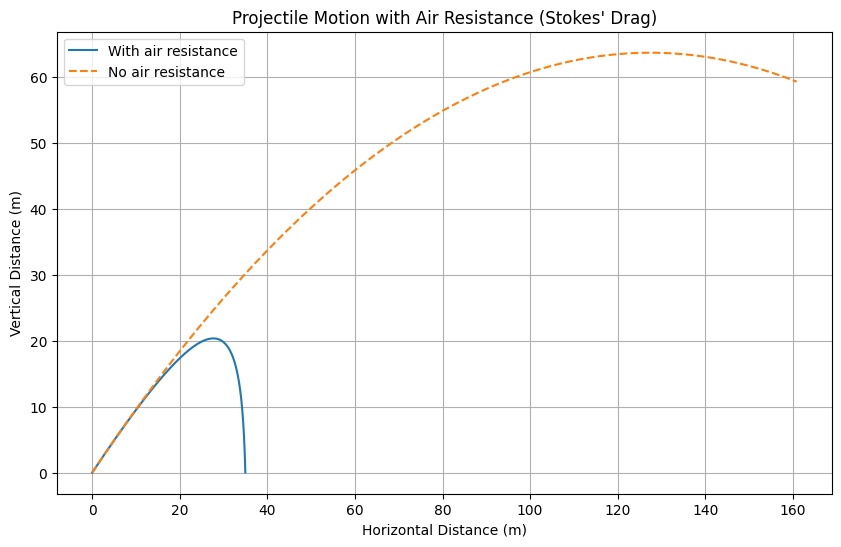

Maximum height with drag: 20.38 m
Maximum height without drag: 63.71 m
Range with drag: 34.98 m
Range without drag: 160.87 m


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

def projectile_motion(y, t, params):
    """Differential equations for projectile motion with air resistance."""
    # Unpack the state vector
    x, y, vx, vy = y

    # Unpack parameters
    g, m, k = params

    # Derivatives
    dxdt = vx
    dydt = vy
    dvxdt = -(k/m) * vx
    dvydt = -g - (k/m) * vy

    return [dxdt, dydt, dvxdt, dvydt]

def simulate_projectile():
    # Simulation parameters
    g = 9.81      # acceleration due to gravity (m/s^2)
    m = 0.1       # mass of projectile (kg)
    v0 = 50       # initial velocity (m/s)
    angle = 45    # launch angle (degrees)
    k = 0.1       # drag coefficient (Stokes' drag: k = 6πηr for a sphere)
    t_max = 10    # maximum simulation time (s)
    dt = 0.01     # time step (s)

    # Convert angle to radians
    theta = np.radians(angle)

    # Initial conditions [x, y, vx, vy]
    y0 = [0, 0, v0 * np.cos(theta), v0 * np.sin(theta)]

    # Time points
    t = np.arange(0, t_max, dt)

    # Parameters to pass to the ODE solver
    params = [g, m, k]

    # Solve the ODEs
    sol = odeint(projectile_motion, y0, t, args=(params,))

    # Extract the solution components
    x = sol[:, 0]
    y = sol[:, 1]
    vx = sol[:, 2]
    vy = sol[:, 3]

    # Find when the projectile hits the ground (y=0)
    idx_ground = np.where(y < 0)[0]
    if len(idx_ground) > 0:
        idx_ground = idx_ground[0]
        t = t[:idx_ground]
        x = x[:idx_ground]
        y = y[:idx_ground]

    # Plot the trajectory
    plt.figure(figsize=(10, 6))
    plt.plot(x, y, label='With air resistance')
    plt.title('Projectile Motion with Air Resistance (Stokes\' Drag)')
    plt.xlabel('Horizontal Distance (m)')
    plt.ylabel('Vertical Distance (m)')
    plt.grid(True)

    # For comparison, plot without air resistance
    if k == 0:
        plt.legend()
        plt.show()
        return

    # Simulate without air resistance for comparison
    params_no_drag = [g, m, 0]  # k=0 means no drag
    sol_no_drag = odeint(projectile_motion, y0, t, args=(params_no_drag,))
    x_no_drag = sol_no_drag[:, 0]
    y_no_drag = sol_no_drag[:, 1]

    # Plot both trajectories
    plt.plot(x_no_drag, y_no_drag, '--', label='No air resistance')
    plt.legend()
    plt.show()

    # Calculate and print some results
    print(f"Maximum height with drag: {max(y):.2f} m")
    print(f"Maximum height without drag: {max(y_no_drag):.2f} m")
    print(f"Range with drag: {x[-1]:.2f} m")
    print(f"Range without drag: {x_no_drag[-1]:.2f} m")

if __name__ == "__main__":
    simulate_projectile()

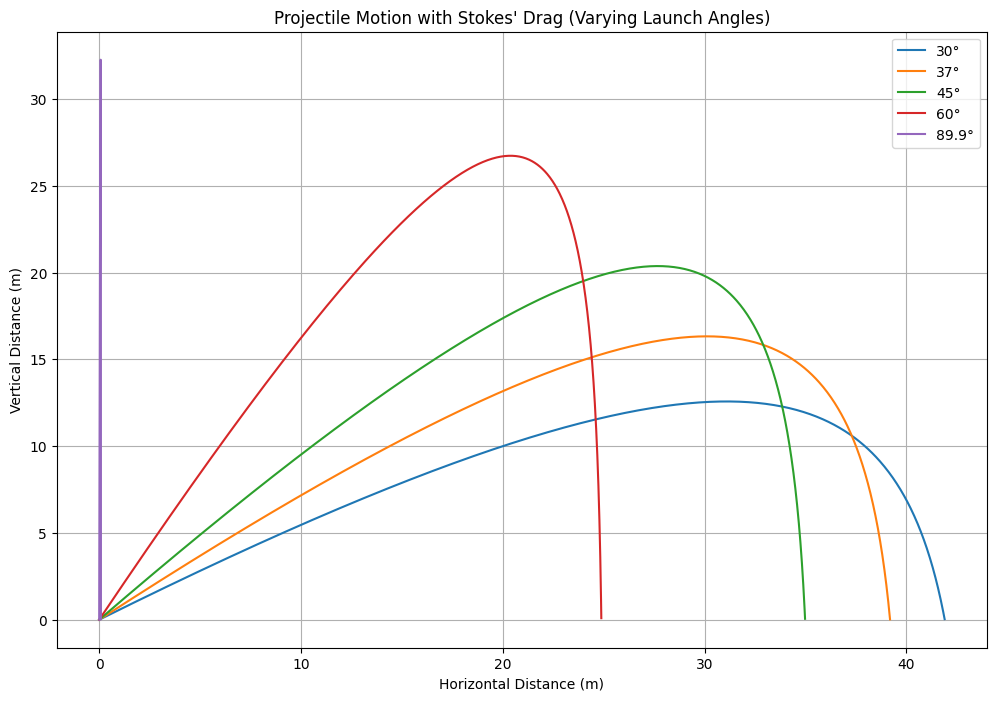

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

def projectile_motion(y, t, params):
    """Differential equations for projectile motion with air resistance."""
    x, y, vx, vy = y      # Unpack state vector
    g, m, k = params      # Unpack parameters

    dxdt = vx             # dx/dt = vx
    dydt = vy             # dy/dt = vy
    dvxdt = -(k/m) * vx   # dvx/dt = -(k/m) vx
    dvydt = -g - (k/m) * vy  # dvy/dt = -g - (k/m) vy

    return [dxdt, dydt, dvxdt, dvydt]

def simulate_multiple_angles():
    # Parameters
    g = 9.81      # gravity (m/s²)
    m = 0.1       # mass (kg)
    v0 = 50       # initial velocity (m/s)
    k = 0.1       # drag coefficient (Stokes' drag)
    t_max = 10    # max simulation time (s)
    dt = 0.01     # time step (s)

    # Launch angles to compare (in degrees)
    angles = [30, 37, 45, 60, 89.9]  # 89.9° ≈ vertical

    plt.figure(figsize=(12, 8))

    for angle in angles:
        theta = np.radians(angle)
        y0 = [0, 0, v0 * np.cos(theta), v0 * np.sin(theta)]  # [x, y, vx, vy]
        t = np.arange(0, t_max, dt)
        params = [g, m, k]

        # Solve ODEs
        sol = odeint(projectile_motion, y0, t, args=(params,))
        x = sol[:, 0]
        y = sol[:, 1]

        # Stop simulation when projectile hits the ground (y < 0)
        idx_ground = np.where(y < 0)[0]
        if len(idx_ground) > 0:
            idx_ground = idx_ground[0]
            x = x[:idx_ground]
            y = y[:idx_ground]

        # Plot trajectory
        plt.plot(x, y, label=f'{angle}°')

    # Plot formatting
    plt.title('Projectile Motion with Stokes\' Drag (Varying Launch Angles)')
    plt.xlabel('Horizontal Distance (m)')
    plt.ylabel('Vertical Distance (m)')
    plt.grid(True)
    plt.legend()
    plt.show()

if __name__ == "__main__":
    simulate_multiple_angles()